# MedicStore (Prework 06)


In [ ]:
# Imports
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

In [ ]:
# Path to the data file
ROOT = Path.cwd() if (Path.cwd() / "data").is_dir() else Path.cwd().parent
DATA_DIR = ROOT / "data"
OUTPUT_DIR = DATA_DIR / "output_v1"
OUTPUT_DIR.mkdir(exist_ok=True)

In [ ]:
# Load the data
sales_part1 = pd.read_csv(DATA_DIR / "Sales_MedicStore_part1.csv", sep=";")
sales_part2 = pd.read_csv(DATA_DIR / "Sales_MedicStore_part2.csv", sep=";")
mapping = pd.read_excel(DATA_DIR / "Mapping.xlsx")
mapping

,Sub-Category,Category
0,Prescription Drugs,Pharmaceuticals
1,Medical Devices,Equipment
2,Over-the-Counter (OTC) Medicines,Pharmaceuticals
3,Diagnostic Tools,Equipment
4,Imaging Systems,Equipment
5,Medical Refrigeration Units,Equipment
6,Surgical Instruments,Equipment
7,Medical Consumables,Supplies
8,Laboratory Reagents,Supplies
9,Wound Care Products,Supplies


In [ ]:
# Concatenation: stack part1 and part2 vertically
sales = pd.concat([sales_part1, sales_part2], ignore_index=True)
print(f"part1: {len(sales_part1)} + part2: {len(sales_part2)} = sales: {len(sales)}")

part1: 19 + part2: 7867 = sales: 7886


In [ ]:
# add the Category column from the mapping table
df_final = sales.merge(mapping, on="Sub-Category", how="left")

# Sanity checks: no line lost, no unknown sub-category
assert len(df_final) == len(sales), "The merge changed the number of lines"
assert df_final["Category"].notna().all(), (
    "Some sub-categories are not in the mapping table"
)
df_final.head()

,City,Country,Customer Name,Manufacturer,Order Date,Order ID,Product Name,Region,Segment,Ship Date,Ship Mode,State/Province,Sub-Category,Quantity,Unit Price,Category
0,West Bromwich,United Kingdom,Ellis Ballard,Canon,02/08/2017,ES-2017-5113958,Medicine 1,North,Corporate,07/08/2017,Second Class,England,Imaging Systems,3,142,Equipment
1,West Bromwich,United Kingdom,Ellis Ballard,Hoover,02/08/2017,ES-2017-5113958,Medicine 2,North,Corporate,07/08/2017,Second Class,England,Medical Refrigeration Units,7,568,Equipment
2,West Bromwich,United Kingdom,Ellis Ballard,Accos,02/08/2017,ES-2017-5113958,Medicine 3,North,Corporate,07/08/2017,Second Class,England,Surgical Instruments,3,14,Equipment
3,Le Bouscat,France,Logan Haushalter,Hon,20/06/2017,ES-2017-2510515,Medicine 4,Central,Consumer,20/06/2017,Same Day,Aquitaine-Limousin-Poitou-Charentes,Over-the-Counter (OTC) Medicines,2,12,Pharmaceuticals
4,Le Bouscat,France,Logan Haushalter,Hamilton Beach,20/06/2017,ES-2017-2510515,Medicine 5,Central,Consumer,20/06/2017,Same Day,Aquitaine-Limousin-Poitou-Charentes,Medical Refrigeration Units,5,488,Equipment


In [ ]:
# Compute the total sales of each line
df_final["total_sales"] = df_final["Quantity"] * df_final["Unit Price"]
df_final[["Quantity", "Unit Price", "total_sales"]].head()

,Quantity,Unit Price,total_sales
0,3,142,426
1,7,568,3976
2,3,14,42
3,2,12,24
4,5,488,2440


In [ ]:
# Export the final dataset to Excel
df_final.to_excel(OUTPUT_DIR / "medicstore_final.xlsx", index=False)

# Answering Questions


In [9]:
# Q1. Number of lines and columns
shapes = {
    "dataset": [
        "Sales_MedicStore_part1.csv",
        "Sales_MedicStore_part2.csv",
        "Mapping.xlsx",
        "final dataset",
    ],
    "nb_lines": [
        sales_part1.shape[0],
        sales_part2.shape[0],
        mapping.shape[0],
        df_final.shape[0],
    ],
    "nb_columns": [
        sales_part1.shape[1],
        sales_part2.shape[1],
        mapping.shape[1],
        df_final.shape[1],
    ],
}
df_shapes = pd.DataFrame(shapes)
df_shapes

,dataset,nb_lines,nb_columns
0,Sales_MedicStore_part1.csv,19,15
1,Sales_MedicStore_part2.csv,7867,15
2,Mapping.xlsx,17,2
3,final dataset,7886,17


In [10]:
# Q2. Column names
list(df_final.columns)

['City',
 'Country',
 'Customer Name',
 'Manufacturer',
 'Order Date',
 'Order ID',
 'Product Name',
 'Region',
 'Segment',
 'Ship Date',
 'Ship Mode',
 'State/Province',
 'Sub-Category',
 'Quantity',
 'Unit Price',
 'Category',
 'total_sales']

In [11]:
# Q3. Top 5 lines
df_final.head(5)

,City,Country,Customer Name,Manufacturer,Order Date,Order ID,Product Name,Region,Segment,Ship Date,Ship Mode,State/Province,Sub-Category,Quantity,Unit Price,Category,total_sales
0,West Bromwich,United Kingdom,Ellis Ballard,Canon,02/08/2017,ES-2017-5113958,Medicine 1,North,Corporate,07/08/2017,Second Class,England,Imaging Systems,3,142,Equipment,426
1,West Bromwich,United Kingdom,Ellis Ballard,Hoover,02/08/2017,ES-2017-5113958,Medicine 2,North,Corporate,07/08/2017,Second Class,England,Medical Refrigeration Units,7,568,Equipment,3976
2,West Bromwich,United Kingdom,Ellis Ballard,Accos,02/08/2017,ES-2017-5113958,Medicine 3,North,Corporate,07/08/2017,Second Class,England,Surgical Instruments,3,14,Equipment,42
3,Le Bouscat,France,Logan Haushalter,Hon,20/06/2017,ES-2017-2510515,Medicine 4,Central,Consumer,20/06/2017,Same Day,Aquitaine-Limousin-Poitou-Charentes,Over-the-Counter (OTC) Medicines,2,12,Pharmaceuticals,24
4,Le Bouscat,France,Logan Haushalter,Hamilton Beach,20/06/2017,ES-2017-2510515,Medicine 5,Central,Consumer,20/06/2017,Same Day,Aquitaine-Limousin-Poitou-Charentes,Medical Refrigeration Units,5,488,Equipment,2440


In [12]:
# Q4. Last 5 lines
df_final.tail(5)

,City,Country,Customer Name,Manufacturer,Order Date,Order ID,Product Name,Region,Segment,Ship Date,Ship Mode,State/Province,Sub-Category,Quantity,Unit Price,Category,total_sales
7881,Bagnolet,France,Katherine Ducich,Acco,22/08/2019,IT-2019-3090371,Medicine 45,Central,Consumer,26/08/2019,Standard Class,Ile-de-France,Wound Care Products,3,51,Supplies,153
7882,Bagnolet,France,Katherine Ducich,Rubbermaid,22/08/2019,IT-2019-3090371,Medicine 661,Central,Consumer,26/08/2019,Standard Class,Ile-de-France,Waiting Room Furnishings,8,110,Furniture,880
7883,Nuremberg,Germany,Laura Armstrong,Cardinal,30/04/2019,ES-2019-4251554,Medicine 205,Central,Corporate,05/05/2019,Standard Class,Bavaria,Wound Care Products,8,49,Supplies,392
7884,Nuremberg,Germany,Laura Armstrong,Acme,30/04/2019,ES-2019-4251554,Medicine 1096,Central,Corporate,05/05/2019,Standard Class,Bavaria,Personal Protective Equipment (PPE),2,39,Supplies,78
7885,Nuremberg,Germany,Laura Armstrong,Stanley,30/04/2019,ES-2019-4251554,Medicine 814,Central,Corporate,05/05/2019,Standard Class,Bavaria,Medical Consumables,12,47,Supplies,564


In [13]:
# Q5. General statistical description (numeric and text columns)
df_describe = df_final.describe(include="all")
df_describe

,City,Country,Customer Name,Manufacturer,Order Date,Order ID,Product Name,Region,Segment,Ship Date,Ship Mode,State/Province,Sub-Category,Quantity,Unit Price,Category,total_sales
count,7886,7886,7886,7886,7886,7886,7886,7886,7886,7886,7886,7886,7886,7886.000000,7886.000000,7886,7886.000000
unique,965,15,792,72,1202,3744,1803,3,3,1317,4,124,17,NaN,NaN,4,NaN
top,London,France,John Murray,Smead,04/08/2017,ES-2017-5776825,Medicine 210,Central,Consumer,08/08/2017,Standard Class,England,Medical Consumables,NaN,NaN,Supplies,NaN
freq,205,2190,28,292,34,12,23,4593,4098,29,4804,1187,1156,NaN,NaN,2888,NaN
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.791022,77.372432,NaN,290.492392
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.221518,105.777411,NaN,488.857501
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,2.000000,NaN,3.000000
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.000000,16.000000,NaN,49.000000
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.000000,37.000000,NaN,117.000000
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.000000,90.000000,NaN,312.000000


In [14]:
# Q1. Number of orders
total_orders = df_final["Order ID"].nunique()
total_orders

3744

In [15]:
# Q2. Total sales amount
total_sales_amount = df_final["total_sales"].sum()
total_sales_amount

np.int64(2290823)

In [16]:
# Q3. Top 3 customers with the most orders
top3_customers = (
    df_final.groupby("Customer Name")["Order ID"]
    .nunique()
    .sort_values(ascending=False)
    .head(3)
)
top3_customers

Customer Name
Frank Olsen       13
Paul Stevenson    12
Yoseph Carroll    12
Name: Order ID, dtype: int64

In [17]:
# Q4. Total sales for France
total_sales_france = df_final.loc[df_final["Country"] == "France", "total_sales"].sum()
total_sales_france

np.int64(650730)

In [18]:
# Q5. Share of France in the total sales
ratio_sales_france = total_sales_france / total_sales_amount
print(f"France represents {ratio_sales_france:.1%} of the total sales")

France represents 28.4% of the total sales


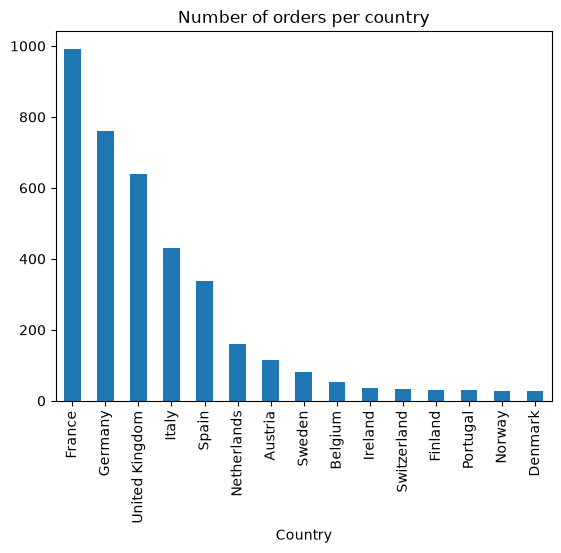

In [19]:
# Number of orders per country
orders_by_country = (
    df_final.groupby("Country")["Order ID"].nunique().sort_values(ascending=False)
)
fig, ax = plt.subplots()
orders_by_country.plot.bar(ax=ax, title="Number of orders per country")
fig.savefig(OUTPUT_DIR / "orders_per_country.png", bbox_inches="tight")

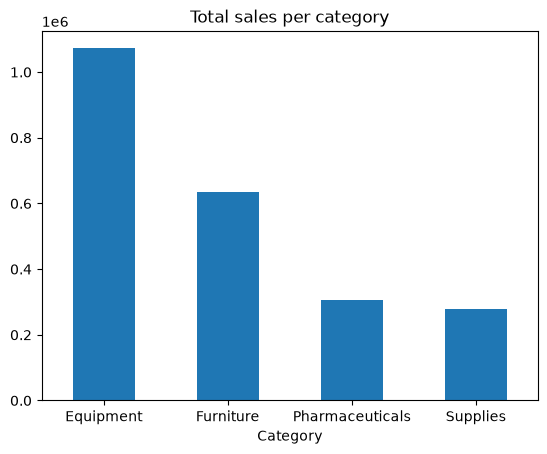

In [20]:
# Total sales per category
sales_by_category = (
    df_final.groupby("Category")["total_sales"].sum().sort_values(ascending=False)
)
fig, ax = plt.subplots()
sales_by_category.plot.bar(ax=ax, title="Total sales per category", rot=0)
fig.savefig(OUTPUT_DIR / "sales_per_category.png", bbox_inches="tight")

In [ ]:
# Store the answers in a dictionary and then a df
dict_analysis = {
    "How many lines are in Sales_MedicStore_part1.csv": len(sales_part1),
    "How many lines are in Sales_MedicStore_part2.csv": len(sales_part2),
    "How many lines are in Mapping.xlsx": len(mapping),
    "How many orders do we have": total_orders,
    "What is the total sales amount": total_sales_amount,
    "Who are the top 3 customers (order count)": ", ".join(top3_customers.index),
    "What is the total Sales for France": total_sales_france,
    "How much does the total Sales for France represent compare to the total global Sales": ratio_sales_france,
}
df_analysis = pd.DataFrame(list(dict_analysis.items()), columns=["Question", "Answer"])
df_analysis

,Question,Answer
0,How many lines are in Sales_MedicStore_part1.csv,19
1,How many lines are in Sales_MedicStore_part2.csv,7867
2,How many lines are in Mapping.xlsx,17
3,How many orders do we have,3744
4,What is the total sales amount,2290823
5,Who are the top 3 customers (order count),"Frank Olsen, Paul Stevenson, Yoseph Carroll"
6,What is the total Sales for France,650730
7,How much does the total Sales for France repre...,0.284059


In [23]:
from openpyxl.drawing.image import Image

In [24]:
# Export the tables and the graphs into one xlsx file and one sheet each
graphs = ["orders_per_country", "sales_per_category"]

with pd.ExcelWriter(
    OUTPUT_DIR / "medicstore_analysis.xlsx", engine="openpyxl"
) as writer:
    df_shapes.to_excel(writer, sheet_name="technical_q1_shapes", index=False)
    df_describe.to_excel(writer, sheet_name="technical_q5_describe")
    df_analysis.to_excel(writer, sheet_name="business_questions", index=False)
    top3_customers.to_excel(writer, sheet_name="business_q3_top3")

    sheet = writer.book.create_sheet("graphs")
    for i, name in enumerate(graphs):
        sheet.add_image(Image(OUTPUT_DIR / f"{name}.png"), f"A{1 + 25 * i}")

print(f"Analysis exported to {OUTPUT_DIR}")

Analysis exported to /Users/kirishanakiritharan/code/emlyon/python_programming_class/kiritharan_course06/data/output_v1
